# Multivariate Analysis

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv(r'D:\new Projects\appliance-energy-forecasting\data\processed\appliances_energy_temporal_features.csv')

In [4]:
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,rv1,rv2,hour,minute,day_of_week,day_name,is_weekend,month,day,date_only
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,13.275433,13.275433,17,0,0,Monday,0,1,11,2016-01-11
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,18.606195,18.606195,17,10,0,Monday,0,1,11,2016-01-11
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,28.642668,28.642668,17,20,0,Monday,0,1,11,2016-01-11
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,45.410389,45.410389,17,30,0,Monday,0,1,11,2016-01-11
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,10.084097,10.084097,17,40,0,Monday,0,1,11,2016-01-11


In [5]:
df.shape

(19735, 37)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 37 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  object 
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9  

In [7]:
numeric_df = df.select_dtypes(include='number')


<Axes: >

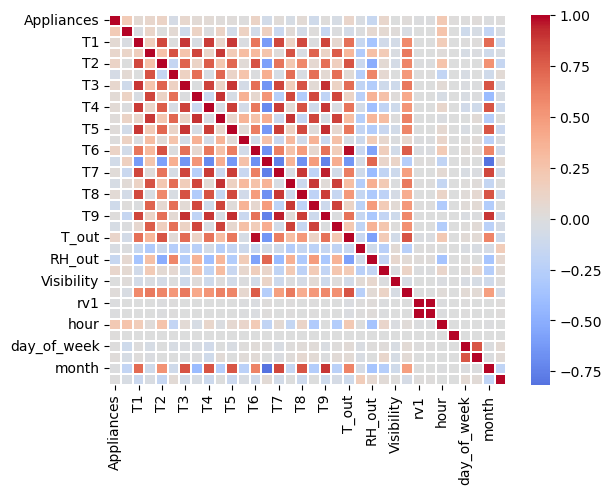

In [8]:
corr_matrix=numeric_df.corr(method='pearson')
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    annot=False,
    linewidths=0.3
)

<Axes: >

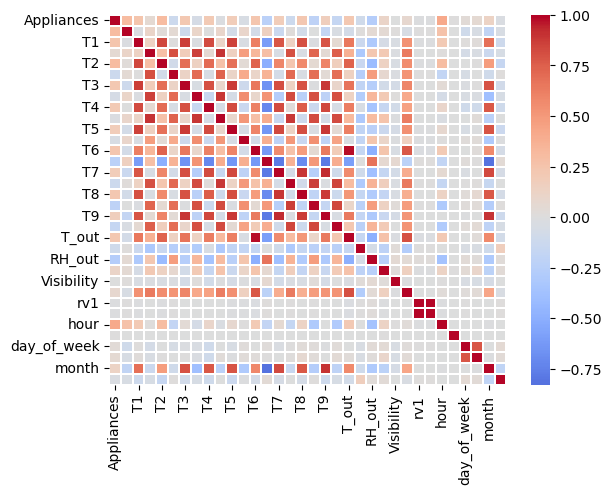

In [9]:
corr_matrix=numeric_df.corr(method='spearman')
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    annot=False,
    linewidths=0.3
)

In [10]:
correlation_df = pd.DataFrame({
    'Pearson': df.corr(numeric_only=True, method='pearson')['Appliances'],
    'Spearman': df.corr(numeric_only=True, method='spearman')['Appliances']
})

correlation_df = correlation_df.drop('Appliances')

correlation_df = correlation_df.sort_values(
    by='Spearman',
    ascending=False
)

correlation_df

,Pearson,Spearman
hour,0.216792,0.416649
T2,0.120073,0.305091
lights,0.197278,0.302420
T1,0.055447,0.244049
T6,0.117638,0.242477
T8,0.039572,0.236147
T3,0.085060,0.216852
T_out,0.099155,0.215504
T4,0.040281,0.207153
T5,0.019760,0.185846


## Hours * Light

In [12]:
df['lights_bin'] = pd.qcut(
    df['lights'],
    q=5,
    duplicates='drop'
)

In [13]:
hour_lights = df.pivot_table(
    index='hour',
    columns='lights_bin',
    values='Appliances',
    aggfunc='mean',
    observed=True
)
hour_lights

lights_bin,"(-0.001, 10.0]","(10.0, 70.0]"
hour,,
0,50.425824,71.063830
1,50.253165,77.812500
2,49.033048,56.000000
3,48.233861,50.000000
4,49.366626,40.000000
5,52.698413,63.333333
6,57.601476,67.777778
7,77.658730,90.000000
8,99.735744,150.873786


<Axes: xlabel='lights_bin', ylabel='hour'>

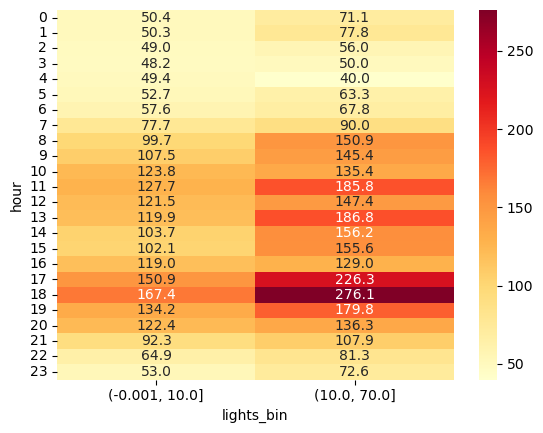

In [14]:
sns.heatmap(
    hour_lights,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd'
)


#### Observation Summary — Hour × Lights
Higher lighting consumption generally coincides with higher appliance consumption across most hours. This difference is particularly noticeable during the morning and evening, with the strongest observed gap at 18:00 (276.15 Wh vs. 167.37 Wh). However, the relationship is not consistent throughout the day; a few hours show only small differences or even a reversed pattern. Overall, lighting consumption appears to provide useful contextual information about appliance consumption, particularly during peak activity hours, although this association does not establish causation.

In [16]:
hour_lights_count = df.pivot_table(
    index='hour',
    columns='lights_bin',
    values='Appliances',
    aggfunc='count',
    observed=True
)

hour_lights_count

lights_bin,"(-0.001, 10.0]","(10.0, 70.0]"
hour,,
0,728,94
1,790,32
2,817,5
3,821,1
4,821,1
5,819,3
6,813,9
7,756,66
8,719,103


#### Hour × Lights (Count Validation)
The count table shows that the two lighting categories are highly imbalanced across several hours.
- The lower lighting bin dominates most hours, generally containing 650–820 observations.
- The higher lighting bin has very few observations overnight (only 1–9 observations between 02:00 and 06:00).
- Higher lighting consumption becomes more frequent during the evening, reaching 174 observations at 18:00 and 269 at 20:00.
- Therefore, the higher appliance consumption observed in the second lighting bin is supported by a reasonable number of observations during evening hours, but comparisons during early morning hours are unreliable because of very small sample sizes.
Overall conclusion: Lighting consumption appears to be a useful contextual feature, particularly during evening hours. However, the imbalance in bin counts means that the mean differences should be interpreted cautiously.

## kitchen temperature (T2) and kitchen humidity (RH_2)--> Appliances

In [19]:
df['T2_bin'] = pd.qcut(
    df['T2'],
    q=5,
    duplicates='drop'
)

df['RH_2_bin'] = pd.qcut(
    df['RH_2'],
    q=5,
    duplicates='drop'
)

In [20]:
t2_rh2 = df.pivot_table(
    index='T2_bin',
    columns='RH_2_bin',
    values='Appliances',
    aggfunc='mean',
    observed=True
)

In [21]:
t2_rh2

RH_2_bin,"(20.462, 37.26]","(37.26, 39.59]","(39.59, 41.5]","(41.5, 43.9]","(43.9, 56.027]"
T2_bin,,,,,
"(16.099, 18.533]",79.636364,82.615039,70.918958,82.119013,68.897516
"(18.533, 19.5]",113.955095,96.006356,93.641536,76.750000,76.291469
"(19.5, 20.5]",105.800241,122.102066,86.842105,96.107383,97.393617
"(20.5, 21.963]",121.167513,108.269485,110.585774,110.846304,95.481283
"(21.963, 29.857]",107.305236,124.730640,112.456140,149.307159,95.068027


<Axes: xlabel='RH_2_bin', ylabel='T2_bin'>

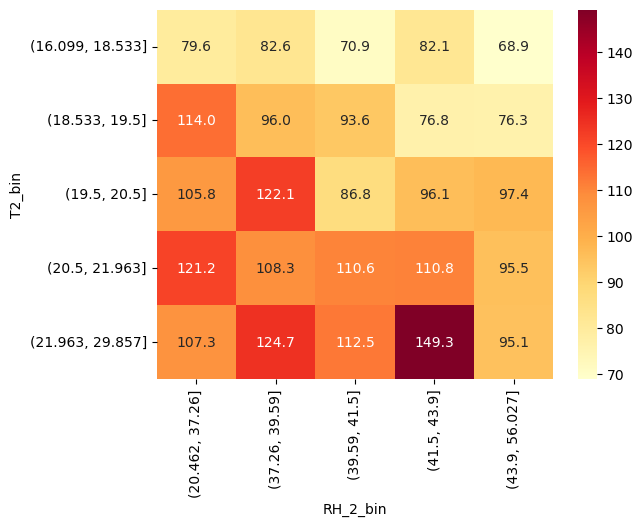

In [22]:
sns.heatmap(
    t2_rh2,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd'
)

#### Observation Summary — T2 × RH_2
- Appliance consumption generally tends to be higher in warmer kitchen-temperature bins, although the increase is not consistent across humidity levels.
- The highest mean consumption (149.31 Wh) occurs in the highest temperature bin (21.963–29.857°C) and the fourth humidity bin (41.5–43.9%).
- At lower temperatures, mean consumption is comparatively lower, mostly around 69–83 Wh in the first temperature bin.
- Humidity does not show a consistent increasing or decreasing relationship with appliance consumption across temperature ranges.
##### Overall conclusion:
 Kitchen temperature appears to show a more noticeable association with appliance consumption than kitchen humidity. Their combined relationship is not uniform, suggesting that other factors may also influence consumption.

In [24]:
t2_rh2_count = df.pivot_table(
    index='T2_bin',
    columns='RH_2_bin',
    values='Appliances',
    aggfunc='count',
    observed=True
)

t2_rh2_count

RH_2_bin,"(20.462, 37.26]","(37.26, 39.59]","(39.59, 41.5]","(41.5, 43.9]","(43.9, 56.027]"
T2_bin,,,,,
"(16.099, 18.533]",385,891,1382,689,644
"(18.533, 19.5]",579,944,703,880,844
"(19.5, 20.5]",831,823,722,894,752
"(20.5, 21.963]",591,757,717,1028,748
"(21.963, 29.857]",1566,594,456,433,882


<Axes: xlabel='RH_2_bin', ylabel='T2_bin'>

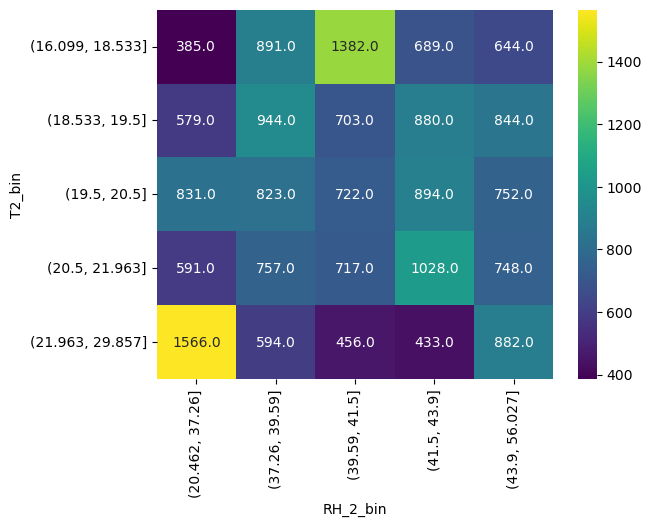

In [25]:
sns.heatmap(
    t2_rh2_count,
    annot=True,
    fmt='.1f',
    cmap='viridis'
)

#### Observation Summary — T2 × RH_2 (Count Validation)
- All 25 temperature–humidity combinations have sufficient observations, ranging from 385 to 1,566 records.
- The highest-temperature and fourth-humidity combination contains 433 observations, so its high mean consumption (149.31 Wh) is not based on an extremely small sample.
- The lowest count is 385, which is still adequate for exploratory comparison.
- The uneven counts should nevertheless be considered when comparing cell averages.
  
##### Overall conclusion:
The observed temperature-related pattern is reasonably supported by the sample counts. Kitchen temperature appears to have a more noticeable association with appliance consumption, while humidity shows no consistent independent pattern.

### T_out × RH_out

In [28]:
df['T_out_bin'] = pd.qcut(
    df['T_out'],
    q=5,
    duplicates='drop'
)

df['RH_out_bin'] = pd.qcut(
    df['RH_out'],
    q=5,
    duplicates='drop'
)


t_out_rh_out_mean = df.pivot_table(
    index='T_out_bin',
    columns='RH_out_bin',
    values='Appliances',
    aggfunc='mean',
    observed=True
)

t_out_rh_out_mean

RH_out_bin,"(23.999, 66.667]","(66.667, 79.333]","(79.333, 87.5]","(87.5, 93.0]","(93.0, 100.0]"
T_out_bin,,,,,
"(-5.001, 2.9]",66.333333,82.307692,96.987654,80.843558,72.484211
"(2.9, 5.633]",128.642857,118.356354,93.553719,81.362530,85.645604
"(5.633, 8.4]",147.911275,108.603561,94.093377,82.583893,92.868757
"(8.4, 11.233]",104.971879,109.208494,82.315668,92.649701,79.439462
"(11.233, 26.1]",125.645604,113.251295,84.031830,89.154519,77.000000


<Axes: xlabel='RH_out_bin', ylabel='T_out_bin'>

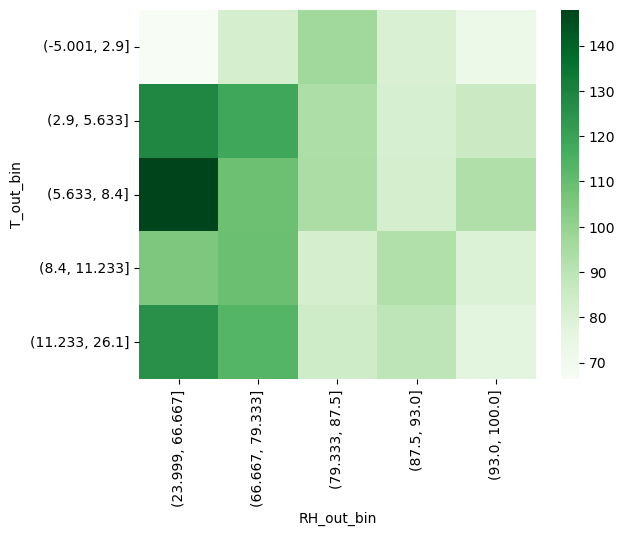

In [29]:
sns.heatmap(t_out_rh_out_mean,cmap='Greens')

#### Observation Summary — T_out × RH_out
Outdoor temperature and humidity do not show a consistent combined relationship with appliance consumption. The highest mean consumption (147.91 Wh) occurs at an outdoor temperature of 5.63–8.4°C and relative humidity of 24–66.67%. Across most temperature ranges, higher outdoor humidity tends to coincide with lower mean appliance consumption, although this pattern is not uniform. Overall, these two outdoor variables provide some contextual information, but their combined relationship with appliance consumption is not particularly strong or consistent.

In [31]:
t_out_rh_out_count = df.pivot_table(
    index='T_out_bin',
    columns='RH_out_bin',
    values='Appliances',
    aggfunc='count',
    observed=True
)

t_out_rh_out_count

RH_out_bin,"(23.999, 66.667]","(66.667, 79.333]","(79.333, 87.5]","(87.5, 93.0]","(93.0, 100.0]"
T_out_bin,,,,,
"(-5.001, 2.9]",60,364,810,1304,1425
"(2.9, 5.633]",280,724,968,1233,728
"(5.633, 8.4]",541,1067,921,596,861
"(8.4, 11.233]",889,1036,868,668,446
"(11.233, 26.1]",2184,772,377,343,270


#### Count Validation — T_out × RH_out
- All 25 combinations have observations, ranging from 60 to 2,184 records.
- Most combinations have several hundred or more observations, providing a reasonable basis for exploratory comparisons.
- The lowest-temperature and lowest-humidity combination has only 60 observations, so its mean (66.33 Wh) should be interpreted cautiously.
- The remaining combinations generally have sufficient sample sizes to support the observed averages.
##### Conclusion: 
The overall interpretation remains unchanged. Outdoor temperature and humidity show some variation in appliance consumption, but no consistent combined pattern emerges.

### Hour* T2

In [34]:
df['T2_bin'] = pd.qcut(
    df['T2'],
    q=5,
    duplicates='drop'
)

hour_t2_mean = df.pivot_table(
    index='hour',
    columns='T2_bin',
    values='Appliances',
    aggfunc='mean',
    observed=True
)

hour_t2_mean

T2_bin,"(16.099, 18.533]","(18.533, 19.5]","(19.5, 20.5]","(20.5, 21.963]","(21.963, 29.857]"
hour,,,,,
0,47.043478,51.120332,54.120879,57.039106,53.333333
1,47.951807,49.365079,54.601227,52.307692,55.647059
2,46.130435,48.477366,50.546875,50.816327,54.189189
3,45.224913,48.695652,50.153846,49.076923,54.545455
4,47.018072,50.165746,51.310345,50.096154,53.833333
5,50.630137,54.852071,50.370370,55.625000,60.701754
6,51.552163,69.190751,55.925926,55.638298,72.962963
7,69.731707,63.698630,123.063063,83.191489,86.557377
8,106.184971,90.853659,114.615385,91.739130,127.256637


<Axes: xlabel='T2_bin', ylabel='hour'>

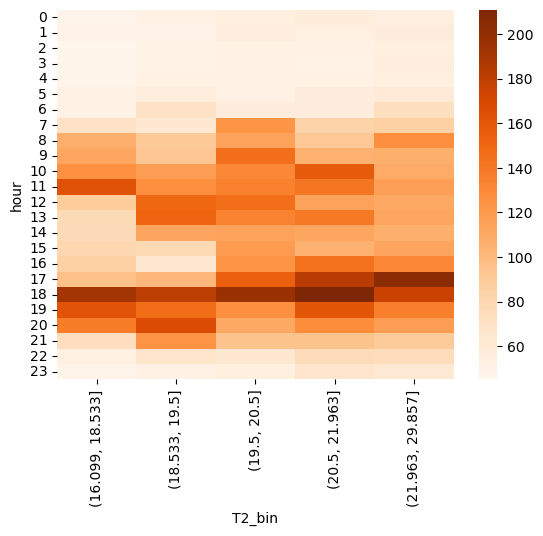

In [35]:
sns.heatmap(hour_t2_mean,cmap='Oranges')

#### Observation Summary — Hour × T2
- Appliance consumption varies considerably by hour, with relatively low values overnight and higher values during daytime and evening hours.
- The highest mean consumption (210.84 Wh) occurs at 18:00 in the fourth temperature bin (20.5–21.963°C).
- At 17:00, consumption also rises noticeably, reaching 204.36 Wh in the highest temperature bin.
- During several daytime hours (09:00–16:00), higher temperature bins do not consistently correspond to higher appliance consumption.
- The evening peak is prominent across nearly all temperature bins, suggesting that time of day has a stronger and more consistent association with appliance consumption than kitchen temperature alone.
##### Overall conclusion: The Hour × T2 combination reveals a strong temporal pattern, but no uniform temperature-related increase across the day. Hour appears to be the more influential contextual variable in this comparison.

In [37]:
hour_t2_count = df.pivot_table(
    index='hour',
    columns='T2_bin',
    values='Appliances',
    aggfunc='count',
    observed=True
)

hour_t2_count

T2_bin,"(16.099, 18.533]","(18.533, 19.5]","(19.5, 20.5]","(20.5, 21.963]","(21.963, 29.857]"
hour,,,,,
0,115,241,182,179,105
1,166,252,163,156,85
2,230,243,128,147,74
3,289,207,130,130,66
4,332,181,145,104,60
5,365,169,135,96,57
6,393,173,108,94,54
7,410,146,111,94,61
8,346,164,130,69,113


<Axes: xlabel='T2_bin', ylabel='hour'>

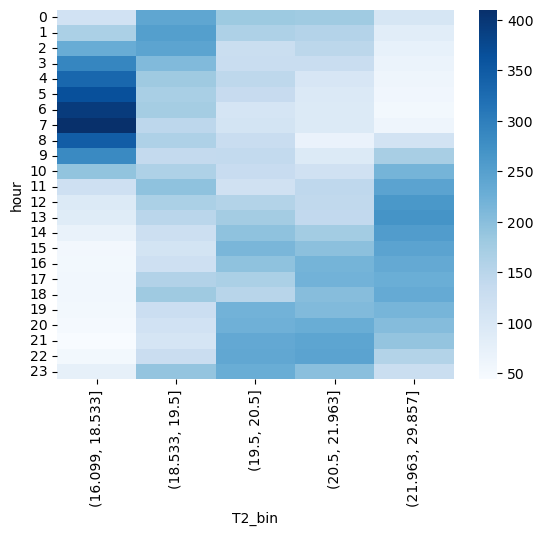

In [38]:
sns.heatmap(hour_t2_count,cmap='Blues')

#### Count Validation — Hour × T2
- All 120 hour–temperature combinations contain observations, ranging from 44 to 410 records.
- Most combinations have sufficient observations for exploratory comparison.
- The lowest count is 44 at 21:00 in the lowest temperature bin. This cell's mean should be interpreted cautiously.
- The evening peak is supported by reasonable sample sizes across all five temperature bins. For example, at 18:00, counts range from 56 to 233.
- The uneven distribution of temperature observations across hours is worth considering when interpreting the heatmap.
##### Overall conclusion: The observed hourly consumption pattern is reasonably supported by the data. Time of day shows a clearer and more consistent relationship with appliance consumption than kitchen temperature. Temperature may provide additional contextual information, but its relationship varies by hour

### Hour × Indoor–Outdoor Temperature Difference

In [41]:
indoor_temp_cols = [
    'T1', 'T2', 'T3', 'T4', 'T5',
    'T6', 'T7', 'T8', 'T9'
]

df['indoor_temp_mean'] = df[indoor_temp_cols].mean(axis=1)

df['indoor_outdoor_temp_diff'] = (
    df['indoor_temp_mean'] - df['T_out']
)

<Axes: xlabel='temp_diff_bin', ylabel='hour'>

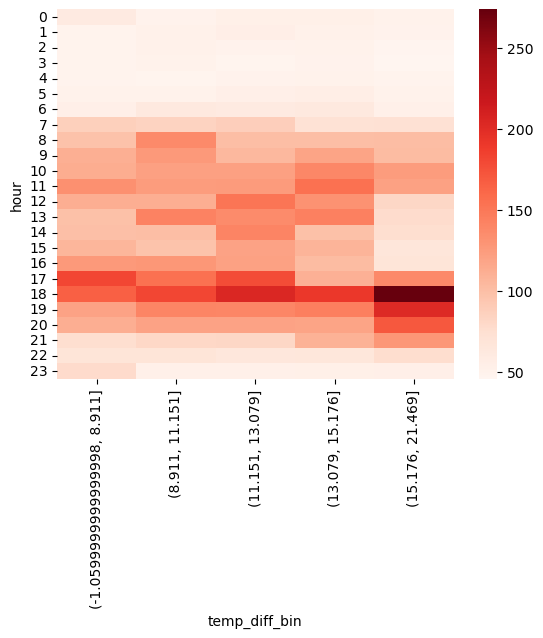

In [42]:
df['temp_diff_bin'] = pd.qcut(
    df['indoor_outdoor_temp_diff'],
    q=5,
    duplicates='drop'
)

hour_temp_diff_mean = df.pivot_table(
    index='hour',
    columns='temp_diff_bin',
    values='Appliances',
    aggfunc='mean',
    observed=True
)

sns.heatmap(hour_temp_diff_mean,cmap='Reds')

In [43]:
hour_temp_diff_mean

temp_diff_bin,"(-1.0599999999999998, 8.911]","(8.911, 11.151]","(11.151, 13.079]","(13.079, 15.176]","(15.176, 21.469]"
hour,,,,,
0,60.824742,50.143885,53.500000,53.024691,50.643939
1,48.787879,51.196581,54.873418,51.363636,50.220588
2,48.494624,51.304348,49.361702,50.443350,47.148148
3,48.961039,50.863309,48.275862,49.478673,45.770609
4,49.218750,48.299320,49.561404,50.676329,48.896552
5,50.961538,50.890411,54.285714,56.387435,51.009772
6,54.117647,62.426471,60.704225,61.896552,52.664577
7,87.241379,84.802632,87.971014,72.356322,73.233333
8,97.674419,136.946565,100.284091,100.222222,101.285141


#### Observation Summary — Hour × Indoor–Outdoor Temperature Difference
- Appliance consumption remains relatively low overnight across all temperature-difference bins.
- Consumption increases substantially during the morning and evening, indicating that time of day remains an important factor.
- The highest mean consumption (273.64 Wh) occurs at 18:00 in the highest temperature-difference bin (15.176–21.469°C).
- At 19:00 and 20:00, the highest temperature-difference bin also shows relatively high consumption (202.29 Wh and 171.17 Wh, respectively).
- However, higher temperature differences do not consistently correspond to higher consumption during daytime hours.
##### Overall conclusion: The indoor–outdoor temperature difference may provide additional contextual information, particularly during evening hours. However, its relationship with appliance consumption varies throughout the day, and the hourly pattern remains more prominent.

In [45]:
hour_temp_diff_count = df.pivot_table(
    index='hour',
    columns='temp_diff_bin',
    values='Appliances',
    aggfunc='count',
    observed=True
)

hour_temp_diff_count

temp_diff_bin,"(-1.0599999999999998, 8.911]","(8.911, 11.151]","(11.151, 13.079]","(13.079, 15.176]","(15.176, 21.469]"
hour,,,,,
0,97,139,160,162,264
1,99,117,158,176,272
2,93,115,141,203,270
3,77,139,116,211,279
4,64,147,114,207,290
5,52,146,126,191,307
6,51,136,142,174,319
7,58,152,138,174,300
8,86,131,176,180,249


<Axes: xlabel='temp_diff_bin', ylabel='hour'>

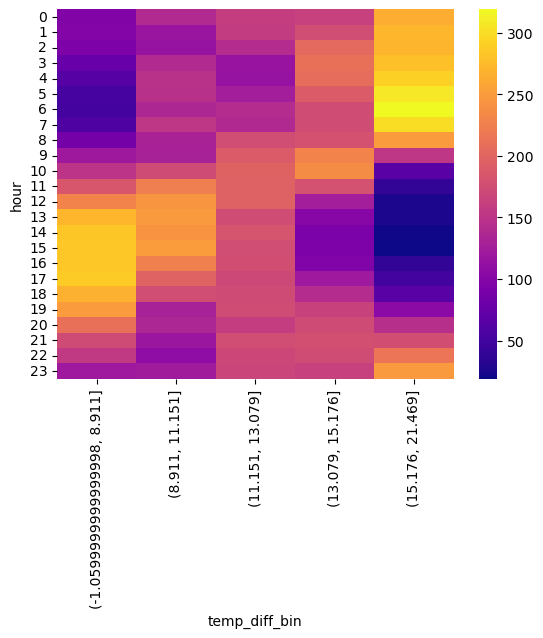

In [46]:
sns.heatmap(hour_temp_diff_count,cmap='plasma')

#### Count Validation — Hour × Indoor–Outdoor Temperature Difference
- All 120 hour–temperature-difference combinations contain observations.
- Counts range from 19 to 319 observations.
- Most combinations have sufficient observations for exploratory analysis.
- The highest temperature-difference bin has very few observations during midday and afternoon hours, particularly at 14:00–16:00 (21, 19, and 39 observations, respectively).
- Therefore, the high consumption observed in the highest bin during evening hours is more credible than comparisons involving the same bin during early afternoon.
##### Overall conclusion: The indoor–outdoor temperature difference may provide useful contextual information during evening hours, but its relationship with appliance consumption is inconsistent across the day. Some daytime comparisons are less reliable because of small sample sizes.

In [48]:
import numpy as np

conditions = [
    df['hour'].between(0, 5),
    df['hour'].between(6, 11),
    df['hour'].between(12, 16),
    df['hour'].between(17, 23)
]

periods = [
    'post_midnight',
    'morning',
    'afternoon',
    'evening_night'
]

df['day_period'] = np.select(
    conditions,
    periods
)

In [49]:
period_summary=df.groupby('day_period')['Appliances'].agg(['count','min','max','mean','median','std'])
period_summary

,count,min,max,mean,median,std
day_period,,,,,,
afternoon,4110,10,900,116.479319,80.0,113.621716
evening_night,5761,20,1080,120.682173,90.0,112.725868
morning,4932,10,860,102.299270,60.0,113.825576
post_midnight,4932,10,380,50.585969,50.0,18.890362


In [50]:
df.columns

Index(['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3',
       'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8',
       'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed',
       'Visibility', 'Tdewpoint', 'rv1', 'rv2', 'hour', 'minute',
       'day_of_week', 'day_name', 'is_weekend', 'month', 'day', 'date_only',
       'lights_bin', 'T2_bin', 'RH_2_bin', 'T_out_bin', 'RH_out_bin',
       'indoor_temp_mean', 'indoor_outdoor_temp_diff', 'temp_diff_bin',
       'day_period'],
      dtype='object')

<Axes: xlabel='day_period', ylabel='Appliances'>

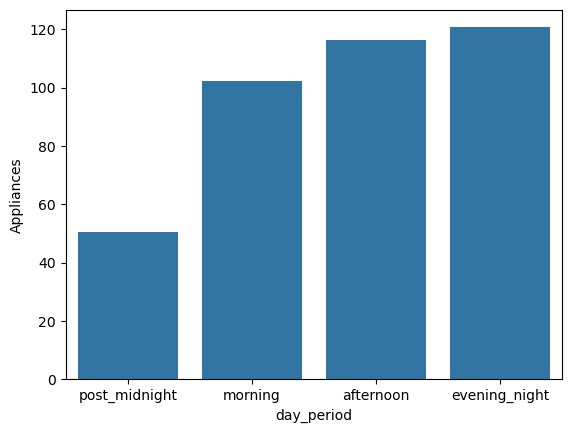

In [51]:
sns.barplot(
    data=df,
    x='day_period',
    y='Appliances',
    order=periods,
    errorbar=None,
    )

#### Key Observations

Post-midnight consumption: This period has the lowest average consumption (50.59 Wh) and considerably lower variability (18.89 Wh), suggesting relatively stable overnight usage.

Morning consumption: Average consumption increases to 102.30 Wh. The difference between its mean and median suggests that some high-consumption intervals influence the average.

Afternoon consumption: Mean consumption rises to 116.48 Wh, indicating higher overall usage compared with the morning.

Evening/night consumption: This period records the highest mean (120.68 Wh) and median (90 Wh), suggesting comparatively higher appliance usage.

Variability: Morning, afternoon, and evening/night have substantially higher standard deviations than post midnight, indicating considerable variation within these periods.

Conclusion

The analysis reveals a noticeable daily consumption pattern. Appliance usage is relatively low and stable after midnight, increases during the morning, and remains higher through the afternoon and evening/night.

The day_period feature will be retained as a candidate categorical predictor for subsequent modeling. Its actual predictive contribution will be assessed using chronological validation rather than inferred from these descriptive statistics alone.



# Multivariate Analysis Report
## Appliance Energy Forecasting

### 1. Project Overview

**Project:** Appliance Energy Forecasting  
**Dataset:** UCI Appliances Energy Prediction  
**Observations:** 19,735  
**Original features:** 29 columns  
**Target variable:** `Appliances`  
**Forecasting objective:** Predict appliance energy consumption at the next 10-minute interval.

### 2. Objective of Multivariate Analysis

The objective of this analysis was to investigate relationships between appliance energy consumption and multiple environmental, temporal, and contextual variables.

The analysis focused on:

- Identifying variables associated with appliance consumption.
- Comparing linear and monotonic relationships.
- Investigating potential interactions between important variables.
- Understanding how temporal and environmental conditions jointly relate to consumption.
- Identifying candidate features for subsequent forecasting models.
- Detecting variables with weak or potentially irrelevant predictive signals.

All findings in this report are exploratory. Relationships observed in the current dataset do not establish causation or guarantee predictive value for future observations.

---

### 3. Correlation Analysis

Pearson and Spearman correlation coefficients were calculated to examine the relationships between numerical features and `Appliances`.

- **Pearson correlation:** Measures the strength and direction of a linear relationship.
- **Spearman correlation:** Measures the strength and direction of a monotonic relationship based on ranks.

#### 3.1 Correlation results

| Feature | Pearson | Spearman |
|---|---:|---:|
| hour | 0.2168 | 0.4166 |
| T2 | 0.1201 | 0.3051 |
| lights | 0.1973 | 0.3024 |
| T1 | 0.0554 | 0.2440 |
| T6 | 0.1176 | 0.2425 |
| T8 | 0.0396 | 0.2361 |
| T3 | 0.0851 | 0.2169 |
| T_out | 0.0992 | 0.2155 |
| T4 | 0.0403 | 0.2072 |
| T5 | 0.0198 | 0.1858 |
| T7 | 0.0258 | 0.1819 |
| T9 | 0.0100 | 0.1670 |
| month | -0.0116 | 0.1259 |
| Windspeed | 0.0871 | 0.1123 |
| Tdewpoint | 0.0154 | 0.0752 |
| is_weekend | 0.0174 | 0.0620 |
| RH_1 | 0.0860 | 0.0605 |
| day_of_week | 0.0031 | 0.0327 |
| minute | 0.0132 | 0.0011 |
| Visibility | 0.0002 | -0.0035 |
| rv2 | -0.0111 | -0.0093 |
| rv1 | -0.0111 | -0.0093 |
| RH_4 | 0.0170 | -0.0202 |
| day | 0.0024 | -0.0230 |
| RH_5 | 0.0070 | -0.0449 |
| RH_3 | 0.0363 | -0.0571 |
| Press_mm_hg | -0.0349 | -0.0962 |
| RH_7 | -0.0556 | -0.1194 |
| RH_2 | -0.0605 | -0.1197 |
| RH_9 | -0.0515 | -0.1646 |
| RH_8 | -0.0940 | -0.2172 |
| RH_6 | -0.0832 | -0.2297 |
| RH_out | -0.1523 | -0.2691 |

#### 3.2 Key positive relationships

**Hour (Spearman: 0.4166)**

Hour has the strongest positive monotonic association with appliance consumption among the examined variables. Consumption tends to increase during particular periods of the day, particularly towards the evening.

Its Pearson correlation is lower (0.2168), suggesting that a simple linear relationship does not fully describe the observed association.

**T2 (Spearman: 0.3051)**

Kitchen temperature has a moderate positive monotonic association with appliance consumption. Its Pearson coefficient is considerably lower (0.1201), indicating that the relationship is not adequately represented by a simple linear correlation.

**Lights (Spearman: 0.3024)**

Lighting consumption also demonstrates a positive monotonic relationship with appliance consumption. Higher lighting levels generally coincide with higher appliance consumption, although this does not establish a causal relationship.

#### 3.3 Key negative relationships

**RH_out (Spearman: -0.2691)**

Outdoor relative humidity has the strongest negative monotonic association among the examined variables.

**RH_6 (Spearman: -0.2297)** and **RH_8 (Spearman: -0.2172)** also demonstrate negative monotonic associations.

These variables may provide environmental context for consumption patterns, although their individual predictive contributions remain unverified.

#### 3.4 Pearson versus Spearman observations

Several variables have noticeably different Pearson and Spearman coefficients.

For example:

- Hour: Pearson 0.2168 versus Spearman 0.4166.
- T2: Pearson 0.1201 versus Spearman 0.3051.
- Lights: Pearson 0.1973 versus Spearman 0.3024.
- RH_out: Pearson -0.1523 versus Spearman -0.2691.

This difference indicates that linear correlation alone may underrepresent some of the observed monotonic associations.

However, differences between these coefficients do not independently prove nonlinearity. Outliers, tied values, skewed distributions, and other distributional characteristics can also affect the results.

---

### 4. Multivariate Relationship Analysis

Five combinations of variables were examined using quantile-based grouping, mean-consumption tables, and corresponding observation-count tables.

The objective was to investigate whether relationships between individual variables and appliance consumption changed under different conditions.

#### 4.1 Hour × Lights

**Observed pattern:**

- Higher lighting-consumption groups generally showed higher average appliance consumption across most hours.
- The difference was particularly noticeable during evening hours.
- At 18:00, mean consumption was approximately 276.15 Wh in the higher lighting group compared with 167.37 Wh in the lower group.
- At 17:00, the corresponding means were approximately 226.35 Wh and 150.87 Wh.

**Data distribution considerations:**

Higher lighting levels were relatively uncommon during overnight hours. Some early-hour combinations contained only one to five observations.

Therefore, the corresponding means should not be interpreted as reliable general patterns.

Evening combinations had considerably more observations and provided stronger descriptive evidence.

**Finding:**

Lighting consumption appears to provide useful contextual information, particularly during evening hours. Its relationship with appliance consumption may vary according to the time of day.

#### 4.2 T2 × RH_2

**Observed pattern:**

- The highest average appliance consumption was approximately 149.31 Wh in the highest T2 group and the RH_2 interval of approximately 41.5–43.9.
- Lower T2 groups generally showed lower average consumption, approximately 69–83 Wh across the examined combinations.
- RH_2 did not demonstrate a consistent monotonic relationship with consumption across all temperature groups.

**Data distribution considerations:**

All 25 combinations were populated. Observation counts ranged approximately from 385 to 1,566.

This provides reasonable support for comparing the grouped averages.

**Finding:**

Kitchen temperature appears to have a more noticeable association with appliance consumption than kitchen relative humidity in this particular combination. The joint relationship is not sufficiently consistent to establish a strong interaction.

#### 4.3 T_out × RH_out

**Observed pattern:**

- The highest mean consumption was approximately 147.91 Wh in the outdoor temperature interval of 5.633–8.4 and the outdoor humidity interval of approximately 24–66.67.
- Across several temperature groups, higher outdoor humidity tended to coincide with lower appliance consumption.
- However, this pattern was not consistent across all combinations.

**Data distribution considerations:**

Observation counts ranged from approximately 60 to 2,184. The smallest combination should be interpreted cautiously.

**Finding:**

Outdoor temperature and humidity provide environmental context, but their combined relationship with appliance consumption is not uniform. Neither variable should be considered an established strong predictor based solely on this analysis.

#### 4.4 Hour × T2

**Observed pattern:**

- The highest mean consumption was approximately 210.84 Wh at 18:00 in the T2 interval of approximately 20.5–21.963.
- Higher consumption was particularly visible during evening hours across multiple temperature groups.
- Temperature-related differences were less consistent during daytime hours.

**Data distribution considerations:**

All combinations contained observations, with counts ranging approximately from 44 to 410.

The lowest-count combinations require more caution than the better-populated groups.

**Finding:**

Time of day appears to have a more prominent association with appliance consumption than kitchen temperature in this comparison. Temperature may provide additional context, but the evening pattern is the more consistent observation.

#### 4.5 Hour × Indoor–Outdoor Temperature Difference

The mean of the nine indoor temperature variables was calculated and compared with outdoor temperature:

`indoor_outdoor_temp_diff = indoor_temp_mean - T_out`

The resulting variable was divided into five quantile-based groups.

**Observed pattern:**

- The highest mean consumption was approximately 273.64 Wh at 18:00 in the highest temperature-difference group.
- The corresponding means were approximately 202.29 Wh at 19:00 and 171.17 Wh at 20:00.
- The relationship was less consistent during daytime and afternoon hours.

**Data distribution considerations:**

Observation counts ranged approximately from 19 to 319.

Some midday and afternoon combinations contained relatively few observations, including 19 observations at 15:00 in the highest temperature-difference group.

These sparse combinations should not be treated as strong evidence.

**Finding:**

The indoor–outdoor temperature difference may provide additional context for evening consumption. However, its relationship with consumption is inconsistent across the day and requires validation in a forecasting model.

---

### 5. Day-Period Analysis

A categorical variable named `day_period` was introduced to represent broad daily consumption patterns.

The four categories were defined as:

- Post midnight: 00:00–05:59
- Morning: 06:00–11:59
- Afternoon: 12:00–16:59
- Evening/night: 17:00–23:59

#### 5.1 Statistical results

| Day Period | Count | Mean (Wh) | Median (Wh) | Std (Wh) |
|---|---:|---:|---:|---:|
| Post midnight | 4,932 | 50.59 | 50 | 18.89 |
| Morning | 4,932 | 102.30 | 60 | 113.83 |
| Afternoon | 4,110 | 116.48 | 80 | 113.62 |
| Evening/night | 5,761 | 120.68 | 90 | 112.73 |

#### 5.2 Key observations

**Post midnight**

This period has the lowest mean consumption (50.59 Wh) and substantially lower standard deviation (18.89 Wh), indicating relatively stable overnight consumption.

**Morning**

Mean consumption increases to 102.30 Wh. The difference between the mean and median indicates that higher-consumption intervals influence the average.

**Afternoon**

Mean consumption rises to 116.48 Wh, suggesting higher overall consumption than during the morning.

**Evening/night**

This period records the highest mean (120.68 Wh) and median (90 Wh), indicating comparatively higher appliance usage.

**Variability**

Morning, afternoon, and evening/night have standard deviations above 112 Wh, showing considerable variability within these periods. Post-midnight consumption is substantially more stable.

#### 5.3 Finding

The analysis identifies a broad daily consumption pattern: relatively low and stable consumption after midnight, increasing consumption during the morning, and higher average consumption through the afternoon and evening/night.

The `day_period` variable will be retained as a candidate categorical feature for forecasting model evaluation.

---

### 6. Exploratory Feature Signal Assessment

Based on the correlation analysis and grouped comparisons, the following features appear worth investigating during model development.

| Feature | Exploratory evidence | Assessment |
|---|---|---|
| hour | Highest Spearman correlation (0.4166); strong daily variation | Strong candidate |
| day_period | Clear differences in consumption across periods | Strong candidate |
| T2 | Spearman correlation 0.3051; grouped temperature differences | Candidate |
| lights | Spearman correlation 0.3024; stronger evening differences | Candidate |
| RH_out | Spearman correlation -0.2691 | Candidate |
| RH_6 | Spearman correlation -0.2297 | Candidate |
| RH_8 | Spearman correlation -0.2172 | Candidate |
| T1, T6, T8, T3 | Positive monotonic associations | Candidates |
| T_out | Positive monotonic association (0.2155) | Candidate |
| Indoor–outdoor temperature difference | Potential evening relationship | Experimental candidate |
| RH_2, RH_9, RH_7 | Negative monotonic associations | Secondary candidates |
| is_weekend | Weak association (0.0620) | Lower priority |
| day_of_week | Very weak association (0.0327) | Lower priority |
| minute | Near-zero association (0.0011) | Lower priority |
| Visibility | Near-zero association (-0.0035) | Lower priority |
| rv1, rv2 | Near-zero association (-0.0093) | Exclude from initial candidate set |

**Important clarification about feature importance:**

This ranking represents exploratory association strength and observed patterns. It is not a formal measurement of feature importance.

Correlation coefficients cannot determine how much a variable contributes to forecasting accuracy. A variable with a weak individual correlation may still provide useful information when combined with other variables. Similarly, a variable with a relatively strong correlation may add little predictive value if its information is already captured by other features.

Actual feature importance must be evaluated after model training using suitable methods such as permutation importance, with validation performed chronologically.

---

### 7. Overall Trends and Patterns Discovered

The combined analysis revealed the following patterns:

1. **Daily timing is an important source of variation.** Hour has the strongest monotonic association with appliance consumption among the examined variables.
2. **Consumption is generally higher during evening hours.** Both hourly analysis and day-period grouping identify higher consumption during the evening and night.
3. **Post-midnight consumption is relatively stable.** This period has considerably lower average consumption and variability.
4. **Lighting consumption provides useful contextual information.** Its association with appliance consumption is particularly noticeable during evening hours.
5. **Kitchen temperature is a potentially useful environmental feature.** Its association is more noticeable when examined using Spearman correlation and grouped comparisons.
6. **Outdoor humidity shows a negative monotonic association.** However, the relationship is not sufficient to establish a causal or reliable forecasting effect.
7. **Environmental interactions are not consistently strong.** Temperature and humidity combinations show some differences, but no uniform joint pattern emerged.
8. **Indoor–outdoor temperature differences may add context.** Their observed association is most noticeable during evening hours.
9. **Weekday and weekend effects appear relatively weak.** The correlation analysis does not identify a strong day-of-week pattern.
10. **Random variables provide no apparent useful signal.** `rv1` and `rv2` have nearly zero correlation with appliance consumption.

---

### 8. Important Limitations

The following limitations must be considered when interpreting the results:

- Correlation does not establish causation.
- Pairwise correlations do not capture every possible nonlinear or conditional relationship.
- Grouped means can be influenced by extreme consumption values.
- Some combinations have relatively low observation counts.
- Quantile binning can produce unequal group sizes and may drop duplicate boundaries when values repeat.
- The dataset covers January to May 2016, so the results cannot establish annual seasonality.
- Environmental and temporal variables may contain redundant information.
- The current analysis is primarily descriptive and does not establish future forecasting performance.
- No formal model-based feature importance or permutation importance has been calculated yet.

### 9. Forecasting Considerations and Leakage Prevention

The project predicts `Appliances` at the next 10-minute interval. Therefore, the distinction between current observations and future target information is essential.

During feature engineering:

1. The dataset must be sorted chronologically.
2. Duplicate timestamps and missing 10-minute intervals must be checked.
3. The target must be aligned with the next 10-minute observation.
4. Time-derived features must correspond to the future target timestamp where appropriate.
5. `day_period` must be derived from the target timestamp, not blindly copied from the current observation.
6. Current `Appliances` must only be used as a predictor if it is explicitly available at forecast time and treated as a legitimate lag feature.
7. No information from future observations may enter the predictor variables.

Model validation must preserve chronological order rather than use a random train-test split.

### 10. Final Conclusion

The multivariate analysis indicates that appliance energy consumption is associated with a combination of temporal, environmental, and contextual variables.

Time of day emerges as the most prominent exploratory signal. The evening period exhibits higher average consumption, while post-midnight consumption is comparatively low and stable. Lighting consumption and kitchen temperature also show notable positive monotonic associations. Outdoor humidity and selected indoor humidity measurements demonstrate negative monotonic associations.

The grouped analyses provide additional context, particularly for the relationships between hour and lighting, hour and kitchen temperature, and hour and indoor–outdoor temperature difference. However, these relationships are not uniformly consistent across all combinations.

The `day_period` feature provides a useful categorical representation of daily consumption patterns and will be retained for model evaluation.

**The next stage is Feature Engineering**, where the forecasting target will be constructed, temporal alignment and data continuity will be verified, and candidate features will be prepared without introducing data leakage.

The ultimate value of these features will be determined by their performance on unseen future observations, not by exploratory correlations alone.

In [90]:
df.to_csv(r'D:\new Projects\appliance-energy-forecasting\data\processed\appliances_energy_temporal_features.csv',
    index=False
)